# analyzing exoplanet data

## 4.1 - 4.2 importing data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
planets = pd.read_csv('exoplanet_data.csv', comment='#')
print(planets.shape)
print(planets.columns.tolist())
print('five unfamiliar columns: pl_bmassj, pl_eqt, st_spectype, pl_orbsmax, sy_dist')

(599, 92)
['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met', 'st_meterr1', 'st_meterr2', 'st_metlim', 'st_metratio', 'st_

## 4.3 reducing data

column descriptions from the nasa exoplanet archive documentation:

- `pl_name`: planet name. this tells me which planet the row is about.
- `hostname`: host name. this is the star or system that the planet orbits.
- `discoverymethod`: discovery method. this tells me how the planet was found.
- `st_spectype`: spectral type. this tells me the general type of the host star based on its spectrum.
- `pl_eqt`: equilibrium temperature in kelvin. this is an estimated temperature based on energy coming in and going out, without necessarily including an atmosphere.
- `pl_bmassj`: planet mass or mass times sin(i), in jupiter masses. this is the planet mass estimate, or a minimum mass when the orbit angle is unknown.

source: https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html

In [3]:
wanted = ['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']
small = planets[wanted]
filtered = small.dropna()
print('smaller data shape:', filtered.shape)
print('rows:', len(filtered), 'columns:', len(filtered.columns))
print('first five:')
display(filtered.head())
print('last five:')
display(filtered.tail())
print('columns:', list(filtered.columns))

smaller data shape: (77, 6)
rows: 77 columns: 6
first five:


,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
6,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
9,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000


last five:


,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
575,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980
580,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000
584,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300
585,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.310


columns: ['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']


## 4.4 analyzing the data

In [4]:
method_counts = filtered['discoverymethod'].value_counts()
print('discovery methods and counts:')
print(method_counts)
print('most common:', method_counts.idxmax(), method_counts.max())
print('least common:', method_counts.idxmin(), method_counts.min())

discovery methods and counts:
discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64
most common: Transit 62
least common: Imaging 2


discovery method definitions:

- transit: the planet blocks a little of its star's light when it passes in front.
- radial velocity: a planet pulls on its star and makes the star move slightly toward and away from us.
- imaging: astronomers take a picture of the planet separately from the light of its star.
- microlensing: gravity bends and magnifies light from a more distant star, which can show a planet.
- transit timing variations: changes in the timing of one planet's transits can reveal another planet.
- eclipse timing variations: a planet can be inferred from changes in the times of eclipses.
- astrometry: the planet is found from a small change in its star's position.

only the methods printed above are present in the filtered data.

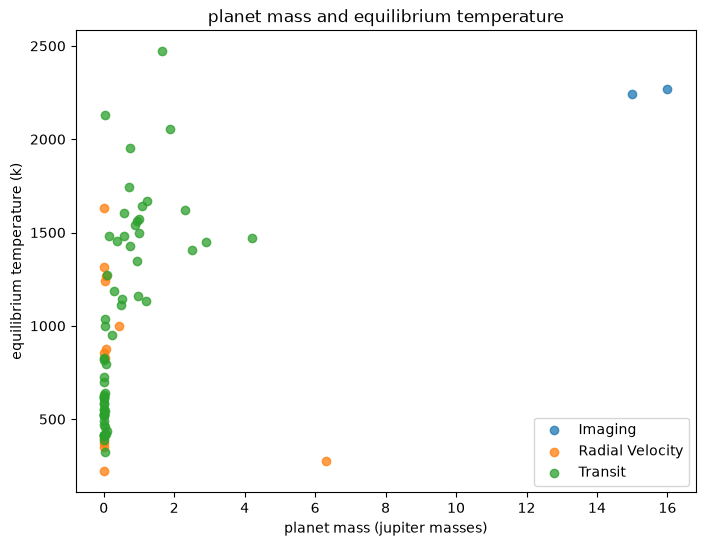

In [5]:
plt.figure(figsize=(8, 6))
for method, group in filtered.groupby('discoverymethod'):
    plt.scatter(group['pl_bmassj'], group['pl_eqt'], label=method, alpha=0.75)
plt.title('planet mass and equilibrium temperature')
plt.xlabel('planet mass (jupiter masses)')
plt.ylabel('equilibrium temperature (k)')
plt.legend()
plt.show()

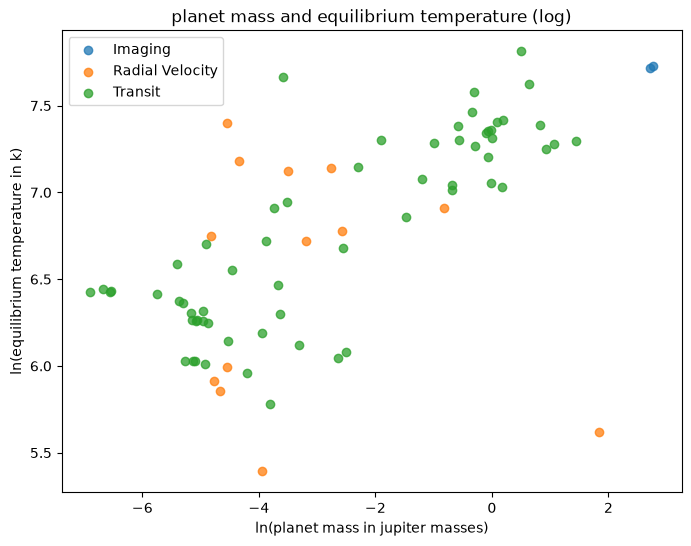

In [6]:
positive = filtered[(filtered['pl_bmassj'] > 0) & (filtered['pl_eqt'] > 0)]
plt.figure(figsize=(8, 6))
for method, group in positive.groupby('discoverymethod'):
    plt.scatter(np.log(group['pl_bmassj']), np.log(group['pl_eqt']), label=method, alpha=0.75)
plt.title('planet mass and equilibrium temperature (log)')
plt.xlabel('ln(planet mass in jupiter masses)')
plt.ylabel('ln(equilibrium temperature in k)')
plt.legend()
plt.show()

imaging generally works best for large planets that are far enough from their stars to be seen separately. the graph lets me compare that pattern with the other discovery methods in this particular sample.

In [7]:
heavy = filtered[filtered['pl_bmassj'] > 5]
coldest = heavy.loc[heavy['pl_eqt'].idxmin()]
print('coldest planet above five jupiter masses:')
print(coldest.to_string())
print('index:', coldest.name)
print('name:', coldest['pl_name'])
print('temperature (k):', coldest['pl_eqt'])
print('mass (jupiter masses):', coldest['pl_bmassj'])
print('star spectral type:', coldest['st_spectype'])
print('the sun is a g2v star; compare this with the spectral type above')

coldest planet above five jupiter masses:
pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
index: 597
name: eps Ind A b
temperature (k): 275.0
mass (jupiter masses): 6.31
star spectral type: K5 V
the sun is a g2v star; compare this with the spectral type above


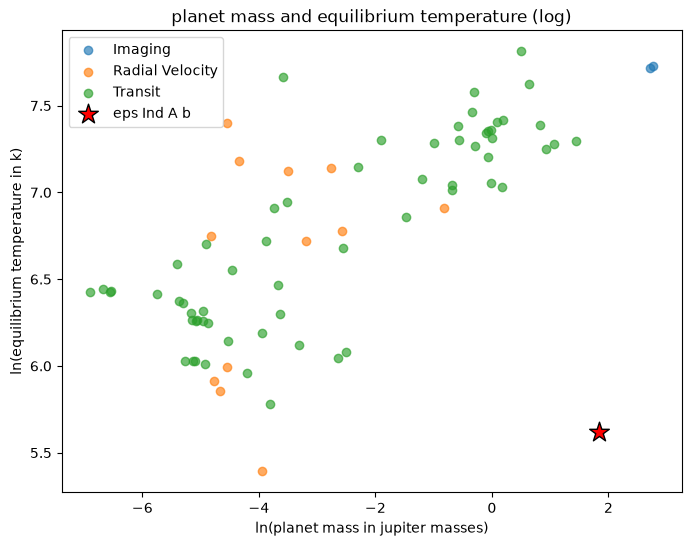

In [8]:
plt.figure(figsize=(8, 6))
for method, group in positive.groupby('discoverymethod'):
    plt.scatter(np.log(group['pl_bmassj']), np.log(group['pl_eqt']), label=method, alpha=0.65)
plt.scatter(np.log(coldest['pl_bmassj']), np.log(coldest['pl_eqt']), color='red', marker='*', s=220, label=coldest['pl_name'], edgecolors='black')
plt.title('planet mass and equilibrium temperature (log)')
plt.xlabel('ln(planet mass in jupiter masses)')
plt.ylabel('ln(equilibrium temperature in k)')
plt.legend()
plt.show()

## 4.5 comparing with the paper

*a temperate super-jupiter imaged with jwst in the mid-infrared* (nature, 2024).

the paper describes eps ind ab, a cold gas giant photographed by the james webb space telescope. it is one of the coldest planets observed through direct imaging. the mass and temperature in the archive may differ from the values in the paper.

https://www.nature.com/articles/s41586-024-07837-8

In [9]:
print('planet from dataset:', coldest['pl_name'])
print('does it match eps ind ab?', 'eps ind' in str(coldest['pl_name']).lower())
print('archive mass (jupiter masses):', coldest['pl_bmassj'])
print('archive equilibrium temperature (k):', coldest['pl_eqt'])
print('the paper discusses atmospheric temperature, which is not directly the same as equilibrium temperature.')

planet from dataset: eps Ind A b
does it match eps ind ab? True
archive mass (jupiter masses): 6.31
archive equilibrium temperature (k): 275.0
the paper discusses atmospheric temperature, which is not directly the same as equilibrium temperature.
